# 4. Evaluation

Schema validity is not correctness, so these checks are separate. Each has a stated sample size.

| Check | Who or what performs it |
|---|---|
| Transcription | WER against manual references |
| Speaker separation | DER against manual reference segments |
| Citations | Automatic validator |
| Grounding of claims | AI-assisted audit (**not human**) |
| Sentiment | AI second reader (**not human**); human worksheet pending |

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, Markdown, display

from calltrace.config import PROJECT_ROOT, load_config
from calltrace.data import AppTekDataset

pd.set_option("display.max_colwidth", 160, "display.max_rows", 80)
config = load_config()
dataset = AppTekDataset(config)
results = config.path("results")
evaluation_dir = results / "evaluation"


In [2]:
metrics = json.loads((evaluation_dir / "metrics.json").read_text(encoding="utf-8"))
print(json.dumps({k: metrics[k] for k in ("selected_calls", "processed_calls", "human_review")}, indent=1))

{
 "selected_calls": 14,
 "processed_calls": 14,
 "human_review": {
  "status": "not reviewed: no human labels yet",
  "labels_completed": 0
 }
}


## Transcription
Protocol: the dataset's scoring steps. Case, punctuation, and speaker labels do not count; number words and digits are normalised. WER is not overall system accuracy.

{
 "calls": 14,
 "channels": 28,
 "reference_words": 19248,
 "pooled_wer_pct": 9.32,
 "median_call_wer_pct": 6.81,
 "min_call_wer_pct": 3.28,
 "max_call_wer_pct": 22.77,
 "agent_pooled_wer_pct": 5.79,
 "customer_pooled_wer_pct": 15.04,
 "normalisation": "dataset score.py protocol, re-implemented; whisper_normalizer package in place of openai-whisper's identical normaliser class"
}


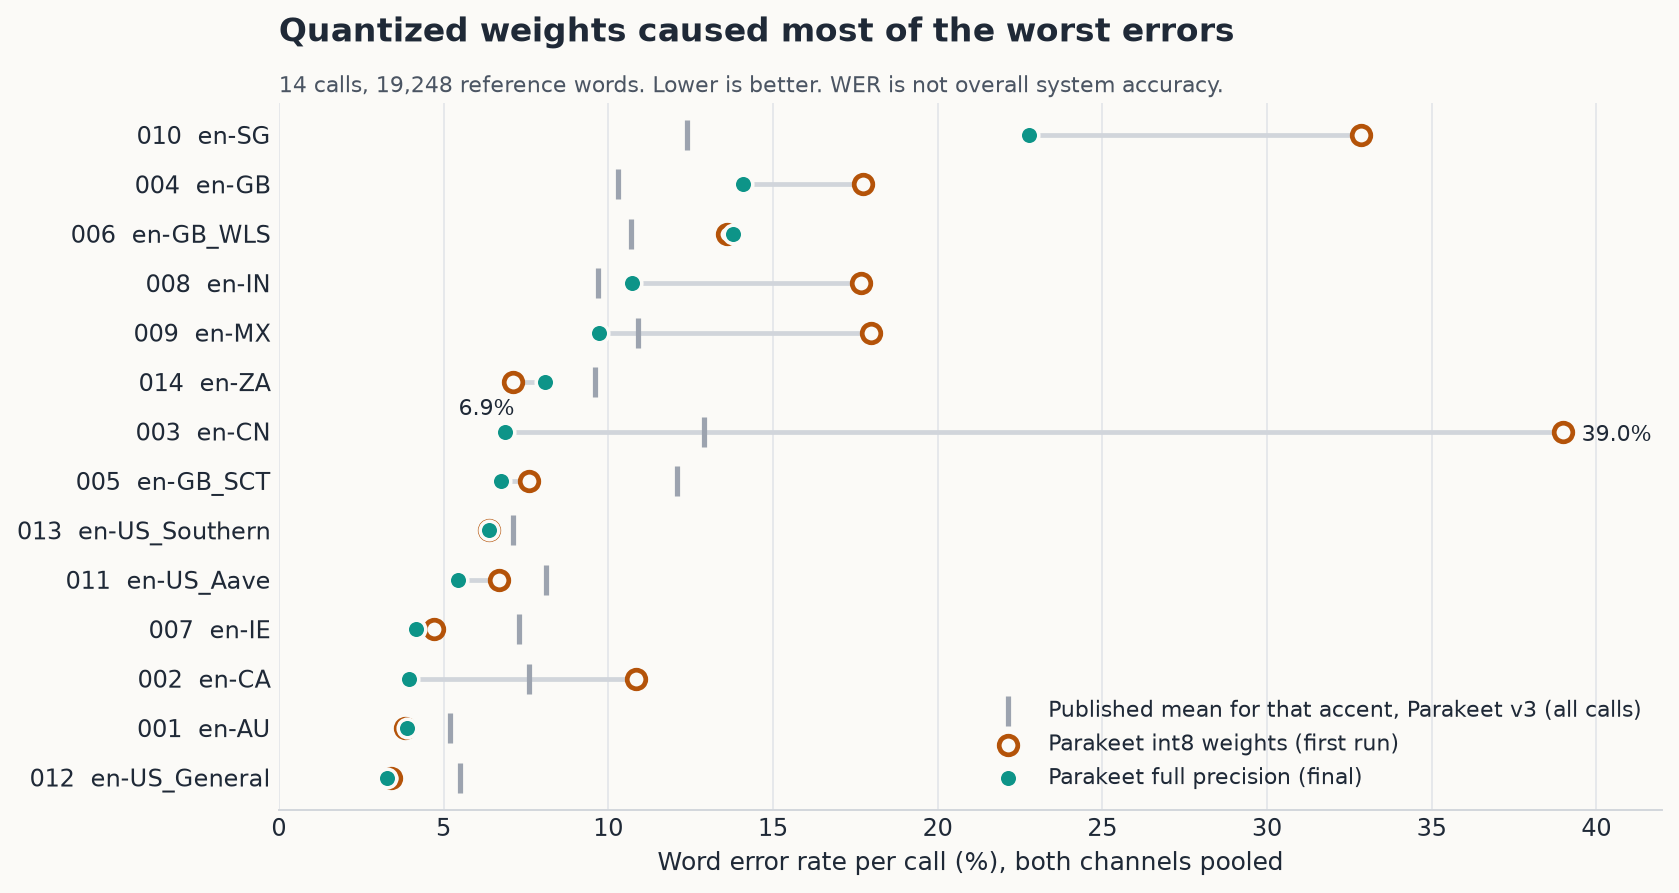

,call_id,accent,domain,reference_words,wer_pct,substitutions,deletions,insertions,agent_wer_pct,customer_wer_pct,published_accent_wer_pct
0,1,en-AU,banking,1640,3.90,25,14,25,4.55,3.03,5.2
1,2,en-CA,realestate,1641,3.96,19,9,37,3.57,4.81,7.6
2,3,en-CN,health,1134,6.88,46,11,21,5.38,9.19,12.9
3,4,en-GB,travel,1859,14.09,116,58,88,11.79,16.07,10.3
4,5,en-GB_SCT,aviation,697,6.74,14,13,20,7.71,5.61,12.1
5,6,en-GB_WLS,energy,1110,13.78,75,30,48,11.42,20.86,10.7
6,7,en-IE,food,2171,4.15,44,34,12,2.14,11.09,7.3
7,8,en-IN,entertainment,1092,10.71,54,23,40,8.23,15.25,9.7
8,9,en-MX,deliveryservice,1256,9.71,59,17,46,5.72,18.30,10.9
9,10,en-SG,telecom,2345,22.77,276,127,131,4.26,35.65,12.4


In [3]:
print(json.dumps(metrics["transcription"], indent=1))
display(Image(config.path("reports") / "figures" / "wer_by_call.png"))
pd.read_csv(evaluation_dir / "wer_per_call.csv")

Fourteen calls, one per accent, cannot rank accents. The published values are for all calls of that accent. The hollow markers are the first int8 run, kept for comparison.

In [4]:
pd.read_csv(evaluation_dir / "wer_top_substitutions.csv").head(20)

,reference -> asr,count
0,the -> a,8
1,its -> is,7
2,will -> would,7
3,bakkar -> baka,5
4,advance -> advanced,5
5,a -> the,4
6,greenberg -> greenburg,4
7,ottowa -> ottawa,3
8,your -> are,3
9,bryan -> brian,3


## Speaker separation

In [5]:
print(json.dumps(metrics["speaker_separation"], indent=1))
pd.read_csv(evaluation_dir / "speaker_separation.csv")

{
 "calls": 14,
 "median_der_pct": 10.23,
 "max_der_pct": 22.67,
 "median_confusion_pct": 0.14,
 "max_confusion_pct": 1.1,
 "collar_s": 0.25,
 "role_phrase_check": {
  "agrees": 14
 },
 "median_word_level_der_pct": 10.16,
 "median_word_level_confusion_pct": 0.15,
 "max_word_level_confusion_pct": 0.63,
 "mono_baseline": {
  "calls": 14,
  "median_der_pct": 6.97,
  "max_der_pct": 50.01,
  "median_confusion_pct": 1.1,
  "max_confusion_pct": 35.23,
  "median_inference_s": 243.0
 },
 "median_reference_overlap_pct": 4.8,
 "max_reference_overlap_pct": 54.2,
 "note": "Speaker identity comes from split channels, so confusion here measures timing overlap, not a clustering decision."
}


,call_id,speakers,agent_channel,role_text_check,der_pct,missed_pct,false_alarm_pct,confusion_pct,scored_speech_s,word_level_der_pct,word_level_missed_pct,word_level_false_alarm_pct,word_level_confusion_pct,n_turns,backchannel_turns,overlapping_turns,reference_overlap_pct,customer_speaks_first_s_before_agent
0,1,Speaker 1=Agent / Speaker 2=Customer,1,agrees (agent cues: 4 vs 1),6.62,0.68,5.74,0.20,495.7,6.47,1.05,5.21,0.20,59,5,33,3.0,0.0
1,2,Speaker 1=Agent / Speaker 2=Customer,1,agrees (agent cues: 3 vs 0),3.17,0.23,2.94,0.00,549.6,3.03,0.64,2.39,0.00,41,0,1,0.0,0.0
2,3,Speaker 1=Agent / Speaker 2=Customer,1,agrees (agent cues: 5 vs 0),2.75,0.16,2.50,0.10,431.9,2.86,0.42,2.35,0.10,39,7,13,3.3,8.9
3,4,Speaker 1=Agent / Speaker 2=Customer,1,agrees (agent cues: 2 vs 0),19.29,1.96,17.17,0.16,505.6,18.26,3.04,14.83,0.38,101,22,80,22.9,0.0
4,5,Speaker 1=Agent / Speaker 2=Customer,1,agrees (agent cues: 1 vs 0),13.83,1.67,12.16,0.00,258.1,12.83,2.67,10.16,0.00,38,4,19,54.2,13.1
5,6,Speaker 1=Customer / Speaker 2=Agent,2,agrees (agent cues: 1 vs 0),14.59,2.09,12.40,0.10,392.2,13.86,3.06,10.64,0.17,51,3,18,4.7,0.0
6,7,Speaker 1=Agent / Speaker 2=Customer,1,agrees (agent cues: 2 vs 0),7.40,0.71,6.56,0.12,684.7,7.12,1.26,5.73,0.12,92,27,50,15.0,0.0
7,8,Speaker 1=Agent / Speaker 2=Customer,1,agrees (agent cues: 2 vs 1),10.40,2.50,7.76,0.14,414.8,12.71,5.20,7.37,0.14,68,5,14,4.8,0.0
8,9,Speaker 1=Agent / Speaker 2=Customer,1,agrees (agent cues: 2 vs 0),7.15,0.81,6.32,0.02,561.4,6.56,1.41,5.14,0.00,51,4,8,0.6,0.0
9,10,Speaker 1=Agent / Speaker 2=Customer,1,agrees (agent cues: 2 vs 0),22.67,2.74,18.82,1.10,608.8,20.15,3.81,15.72,0.63,125,28,82,14.6,1.7


### Baseline: diarization on the merged mono file
This is a contrast only. The main pipeline does not use it.

In [6]:
baseline = evaluation_dir / "mono_diarization_baseline.csv"
pd.read_csv(baseline) if baseline.exists() else print("Baseline not run")

,call_id,der_pct,missed_pct,false_alarm_pct,confusion_pct,inference_s,audio_s
0,1,2.77,1.64,0.31,0.82,246.9,633.177
1,2,4.29,3.91,0.02,0.36,239.1,690.862
2,3,5.96,5.96,0.00,0.00,194.3,519.861
3,4,50.01,14.68,0.10,35.23,258.2,624.467
4,5,12.14,7.26,1.24,3.64,138.3,358.734
5,6,5.74,5.12,0.61,0.01,283.0,582.360
6,7,3.36,1.75,0.34,1.27,483.6,902.865
7,8,20.78,17.13,0.25,3.40,231.2,586.133
8,9,3.14,2.37,0.44,0.34,408.0,781.155
9,10,12.23,5.15,0.01,7.07,406.9,888.000


## Citation checks
These show that citations exist and quotes match. They do not show that a claim is correct.

In [7]:
print(json.dumps(metrics["output_validation"], indent=1))

{
 "calls": 14,
 "calls_passing_validation": 11,
 "citations_checked": 275,
 "repair_retries": 10,
 "claims_stated": 40,
 "claims_unclear": 2,
 "claims_not_stated": 0,
 "failing_errors": [
  "agent_acknowledged_issue: answer 'yes' cites no turn",
  "concrete_action_or_next_step: answer 'yes' cites no turn",
  "resolution: answer 'unresolved' cites no turn",
  "agent_action: quote not found in 009-T0013: \"Okay, we provide standard insurance coverage up to one hundred dollars automatically. That's for default, but for items like this kind of expensive glassware, we strongly recommend purchasing supplemental insurance just to cover the full declared replacement value.\"",
  "agent_action: quote not in 009-T0013: \"Okay, we provide standard insurance coverage up to one hundred dollars automatically. That's for default, but for items like this kind of expensive glassware, we strongly recommend purchasing supplemental insurance just to cover the full declared replacement value.\". Exact tur

## Grounding audit
**AI-assisted, not human.** The development assistant read each claim with its cited turns and the manual reference. Reviewers should treat it as a first pass.

In [8]:
print(metrics["grounding_ai_audit_notice"])
print(json.dumps(metrics["grounding_ai_audit"], indent=1))
audit = json.loads((evaluation_dir / "grounding_audit_ai.json").read_text(encoding="utf-8"))
pd.DataFrame(audit["items"])[["claim_id", "cited_support", "correct_in_call", "reason"]]

AI-assisted audit by the development assistant (Claude Opus 5.5), a different model from the one that wrote the summaries. It is NOT a human annotation and NOT independent human validation.
{
 "auditor": "AI-assisted audit by the development assistant (Claude Opus 5.5). NOT a human annotation and NOT independent human validation.",
 "claims": 42,
 "cited_support": {
  "supported": 20,
  "partially": 22
 },
 "correct_in_call": {
  "yes": 34,
  "partly": 7,
  "no": 1
 },
 "cited_support_by_type": {
  "issue": {
   "supported": 9,
   "partially": 5
  },
  "action": {
   "partially": 11,
   "supported": 3
  },
  "outcome": {
   "partially": 6,
   "supported": 8
  }
 }
}


,claim_id,cited_support,correct_in_call,reason
0,001-issue,supported,yes,Customer says they sent money to the wrong place.
1,001-action,partially,yes,Verification and recall are cited. Locating the transaction happens in an uncited turn.
2,001-outcome,partially,partly,Drops the hedge: the agent said the amount 'should hopefully appear' and earlier gave no guarantee.
3,002-issue,partially,yes,The business trip is not in the cited turns.
4,002-action,partially,yes,'Bachelor' is not in the cited turns.
5,002-outcome,supported,yes,Agent suggests checking the website and says they will send details to the noted email.
6,003-issue,partially,partly,ASR heard 'prescription review'; the reference says 'prescription refill'. The error reached the summary.
7,003-action,supported,yes,Details requested and the Tuesday slot locked in.
8,003-outcome,supported,yes,Tuesday 11 AM confirmed; script to be sent by 5 PM after doctor review.
9,004-issue,supported,yes,"Customer asks about cabin availability, meals, and price for Dubai."


## Sentiment
No independent human labels exist yet. `reports/human_review_worksheet.xlsx` is ready for a person to complete. The comparison below uses an AI second reader, which is **not** independent human validation.

In [9]:
print(json.dumps(metrics["sentiment_ai_second_reader"], indent=1))
pd.read_csv(evaluation_dir / "sentiment_second_reader_comparison.csv")

{
 "reader": "AI second reader: the development assistant (Claude Opus 5.5). NOT a human annotation and NOT independent human validation. The reader had already seen the pipeline's labels, so this comparison is not blind.",
 "calls": 14,
 "agreements": {
  "overall": 8,
  "beginning": 13,
  "ending": 12,
  "resolution": 12
 }
}


,call_id,overall_pipeline,overall_second_reader,beginning_pipeline,beginning_second_reader,ending_pipeline,ending_second_reader,resolution_pipeline,resolution_second_reader,second_reader_note
0,1,positive,mixed,negative,negative,positive,positive,unresolved,unresolved,"Worried at first, then relieved and full of praise. The refund is still pending."
1,2,positive,neutral,neutral,neutral,positive,neutral,unresolved,unresolved,Polite questions. 'Looking forward to it' reads as courtesy.
2,3,positive,positive,neutral,neutral,positive,positive,confirmed,confirmed,"'So easy', 'I was so stressed before' is tied to something specific."
3,4,positive,positive,neutral,neutral,positive,positive,confirmed,unresolved,"Repeated 'lovely', 'can't wait'. The deposit and booking are deferred to a call tomorrow."
4,5,positive,neutral,neutral,neutral,positive,neutral,unresolved,unclear,"Channels are out of sync, so order is unreliable. 'Quite helpful' reads as a polite close."
5,6,positive,neutral,neutral,neutral,neutral,neutral,unresolved,unresolved,Information questions throughout.
6,7,positive,positive,neutral,neutral,positive,positive,unresolved,unresolved,"'Fantastic', 'wonderful, amazing'. Drinks and the emailed confirmation are still open."
7,8,positive,mixed,negative,negative,positive,positive,confirmed,confirmed,'Pretty annoyed' at first; the reference has 'no ads this time' before the close.
8,9,positive,positive,neutral,neutral,positive,positive,confirmed,confirmed,'That puts my mind at ease' is specific. Pickup was scheduled in the call.
9,10,mixed,mixed,neutral,neutral,positive,positive,confirmed,confirmed,"Complains about the installer and sales calls, then calls the agent a lifesaver. Hard audio."


## Experiment: does transcription error change the analysis?
Same analysis configuration on ASR text and on the manual reference, for calls at evenly spaced WER ranks.

In [10]:
print(json.dumps(metrics["asr_vs_reference"], indent=1))
comparison = pd.read_csv(evaluation_dir / "asr_vs_reference.csv")
comparison[comparison.field.isin(["resolution", "sentiment_overall", "sentiment_beginning", "sentiment_ending", "sentiment_change"])]

{
 "calls": [
  "005",
  "007",
  "008",
  "010",
  "012"
 ],
 "label_fields_compared": 25,
 "label_fields_matching": 20,
 "text_fields_for_manual_comparison": 15,
 "skipped_calls": []
}


,call_id,field,on_asr,on_reference,exact_match
3,5,resolution,unresolved,unresolved,True
4,5,sentiment_overall,positive,positive,True
5,5,sentiment_beginning,neutral,neutral,True
6,5,sentiment_ending,positive,negative,False
7,5,sentiment_change,improved,worsened,False
11,7,resolution,unresolved,unresolved,True
12,7,sentiment_overall,positive,positive,True
13,7,sentiment_beginning,neutral,neutral,True
14,7,sentiment_ending,positive,positive,True
15,7,sentiment_change,improved,improved,True


In [11]:
comparison[comparison.field.isin(["issue", "action", "outcome"])]

,call_id,field,on_asr,on_reference,exact_match
0,5,issue,The customer wants to change their flight from tomorrow to Wednesday after six o'clock.,The customer wanted to change their flight booking due to potential bad weather.,False
1,5,action,The agent checked availability and found the last seat available for the 9:30 flight.,The agent searched for available seats and identified a fee for the change.,False
2,5,outcome,"The agent requested payment details which the customer declined, and the call ended without confirming the change.",The agent offered to book the change but the customer declined payment.,False
8,7,issue,"The customer wanted to inquire about catering services for a birthday brunch with 15 people, including dietary restrictions for gluten-free guests.",Sarah called to inquire about catering services for a birthday brunch.,False
9,7,action,"The agent explained menu options, pricing, delivery times, and additional service packages available for the event.","The agent gathered details, presented menu options, and calculated pricing.",False
10,7,outcome,The agent agreed to send an email confirmation and noted that payment would be collected on the day of the event.,The agent agreed to send an email confirmation and noted the customer would decide on drinks later.,False
16,8,issue,The customer reported receiving ads despite having a premium subscription.,The customer reported receiving ads despite having a premium subscription.,True
17,8,action,The agent verified the customer's email and guided them through clearing the app cache.,The agent verified the customer's email and confirmed the premium subscription was active.,False
18,8,outcome,"The customer cleared the cache and confirmed ads were gone, but the agent offered further premium features.","The agent guided the customer to clear the app cache, which resolved the ad issue.",False
24,10,issue,The customer reported Wi-Fi setup issues and later requested to add football channels.,The customer reported Wi-Fi setup issues after installers arrived and asked for assistance.,False


## Prompt change, held-out check
Prompt v1 marked 9 of 14 calls as `confirmed` even when something was only started or promised. Prompt v2 tightened that rule and left 5 of 14 on the same transcripts.
This tuning used the sample itself, so the final labels are not a clean test. The pilot call was held out as one small check.

In [12]:
pilot_call = json.loads((results / "pilot" / "calls" / "pilot" / "analysis.json").read_text(encoding="utf-8"))
print("Pilot resolution on prompt v2:", pilot_call["handling"]["resolution"])
print("Pilot citation check passed:", pilot_call["validation"]["passed"])

Pilot resolution on prompt v2: {'answer': 'confirmed', 'note': 'The booking was completed and the customer received confirmation details.', 'evidence': [{'turn_id': 'pilot-T0043', 'quote': 'All right, and it looks like that went through.', 'speaker': 'Agent', 'start': 489.25, 'end': 509.33}]}
Pilot citation check passed: True


## Error analysis
Real successes and failures, with short excerpts and plausible causes.

In [13]:
display(Markdown((evaluation_dir / "error_analysis.md").read_text(encoding="utf-8")))

# Error analysis

Representative successes, failures, and ambiguous cases from the final run (Parakeet full precision, prompt v2).
Judgments here come from the AI-assisted audit and **are not human annotations**. Short excerpts are from the
role-played dataset. "Reference" is the dataset's manual transcript.

## Successes

**Call 001, banking: evidence that holds up.** The summary says the customer sent money to the wrong person.
It cites `001-T0002` at 18.4 s: "I've realized I've sent it to the wrong place." The ASR text matches the reference
closely here, and WER on this call is 3.90%.

**Call 001, resolution after the prompt fix.** Prompt v1 said resolution was `confirmed`. Prompt v2 says `unresolved`.
That fits the evidence: the agent said the amount "should hopefully appear as a pending refund".

**Call 014, sentiment change.** The customer opens with "I'm upset and angry." (`014-T0004`), later turns are calm,
and the change is `improved`. The label comes from a fixed rule, not from the model's impression of the call.

## Failures

**Call 005, aviation: a real citation supports a wrong conclusion.**
The summary says the customer declined to give payment details, and it cites `005-T0026` and `005-T0027`.
Those turns exist and the quotes match, so every mechanical check passes.
But the customer gives card digits at 1.5 s and a sort code at 26.7 s, while the agent's greeting is at 14.7 s and the
agent only repeats that sort code at 340.9 s. The reference has the same order and overlap (54%), so this comes from the recordings: the two channels
appear to be out of sync. "No thank you" seems to answer a different question.
*Cause:* out-of-sync channels. *What the project now does:* flags calls whose speakers overlap on over 30% of the quieter
speaker's time. This threshold was chosen after seeing this call, and only this call in the sample passes it.
*Lesson:* traceability lets a reviewer find this error, but it does not prevent it.

**Call 003, ASR error reaches the summary.** ASR heard "prescription review"; the reference says "prescription refill".
The summary repeats "review". *Cause:* recognition error on a key word. The quote check passes, because it compares
with the ASR text and not with what was really said.

**Calls 006 and 014, failed citation checks.** Call 006 answers three handling questions with no citation.
Call 014 cites "two four two seven one zero." in `014-T0048`, which does not contain it (the digits are in another turn).
Call 009 quotes a sentence that is not in the turn it cites. The validator catches all three, the retries do not fix
them, and the outputs stay marked as failed instead of being dropped.

**Customer sentiment leans on politeness.** The overall label is `positive` for 10 of 14 calls. The AI second reader
agrees with the overall label on only 8 of 14 calls, against 13 of 14 for the beginning label and 12 of 14 for the ending label.
In call 002 the evidence includes "Thank you very much."; in call 006, "Thank you, bye for now." The courtesy filter also missed
that second turn, because "now" is not in its word list.
*Cause:* the rule against treating thanks as sentiment is only an instruction for the overall label; the code filter is imperfect.
*Status:* not fixed. Treat overall sentiment as weak until human labels exist.

**Call 012, sentiment label flips on nearly identical text.** The beginning label is `positive` on ASR text and `neutral`
on the reference, though this call has the lowest WER (3.28%). The justification treats "It's actually a special occasion
for us." as enthusiasm. *Cause:* model instability on a borderline turn, and the reference's segmentation also differs. Word errors are not the likely cause.

## Ambiguous cases

**Call 010, telecom: the hardest audio.** Customer-channel WER is 35.65%, against 4.26% for the agent, on the same call.
Parakeet and Whisper both struggle (35.65% and 36.59%), so the model is not the main cause. The summary still gets the
main points right, but evidence is weak: the ASR has "And then the other day, uh fix everything" where the reference has
"installers just now just came, and then they already (uh) fix everything".

**Call 011, finance: the recording ends mid-question.** The outcome is marked `unclear`, which is right, but no one can tell
from the data whether the role-play was stopped early or the file was cut.

**Call 013, retail: the ending.** The last customer turns are repeated "Hello?" with no reply. The ending window correctly
ignores them as non-substantive, so the label reflects the turns before them. Whether the call dropped cannot be known from the transcript.

## Diagnosing the transcription errors

The first full run used int8 weights and gave 14.39% pooled WER, with one call at 38.98%. Deletions dominated.

1. **Hypothesis: the VAD or low level loses speech.** Rejected. A more sensitive VAD and peak normalisation did not help on 7 test channels (for example 45.78% vs 46.08% and 47.53% on call 003's agent channel).
2. **Hypothesis: the voices are simply hard.** Rejected for most channels. Whisper large-v3 scored 6.83% on that same channel.
3. **Hypothesis: int8 quantization.** Supported. Full-precision Parakeet scored 5.38% on that channel with the same VAD and audio.

The final run uses full precision: 9.32% pooled WER, close to the 9.2% average published for this model.
The pilot call hid this problem, scoring 6.02% with int8. A small easy check can pass while a harder sample fails.

## Speaker separation: what the numbers do and do not show

Channel-based separation has median DER 10.23%; the mono baseline, 6.97%. So the baseline wins on overall DER.
Most of the channel-based error is false alarm. Word ends are estimated from the next token's start, so spans can run past
the actual speech. Using word spans instead of turn spans barely changes it (10.16%), so pauses inside turns are not the main cause.

Speaker confusion is what matters for attributing a claim to the right person, and there the channels win: at most 1.1%,
against up to 35.23% on call 004 for the baseline. The baseline also needed the reference to map its clusters to speakers,
which a real deployment could not do. Channels are not always available: this result does not apply to mono recordings.


## Runtime

In [14]:
print(json.dumps(metrics["runtime"], indent=1))
pd.read_json(results / "runtime.jsonl", lines=True).query("step == 'call'")[["call_id", "audio_s", "transcription_s", "analysis_s", "turns"]]

{
 "hardware": "AMD Ryzen 7 6800H (8 cores), 15 GB RAM; ASR on CPU; LLM on RTX 3050 Ti 4 GB via Vulkan",
 "asr_model_load_s_cached_weights": 5.34,
 "calls_timed": 14,
 "median_transcription_s_per_audio_minute": 7.5,
 "median_analysis_s_per_call": 45.5,
 "max_analysis_s_per_call": 70.4,
 "note": "Timed during normal use of the machine. Some LLM answers came from the cache."
}


,call_id,audio_s,transcription_s,analysis_s,turns
1,1.0,633.177,89.71,65.40,59.0
2,2.0,690.862,75.81,57.84,41.0
3,3.0,519.861,60.39,38.62,39.0
4,4.0,624.467,81.87,61.54,101.0
5,5.0,358.734,49.75,48.85,38.0
6,6.0,582.360,68.19,29.61,51.0
7,7.0,902.865,119.16,46.56,92.0
8,8.0,586.133,80.87,30.22,68.0
9,9.0,781.155,83.44,70.38,51.0
10,10.0,888.000,124.20,44.44,125.0


## Results table

In [15]:
display(Markdown((evaluation_dir / "results_table.md").read_text(encoding="utf-8")))

| Check | Result | Sample | Compared against |
|---|---|---|---|
| Transcription: pooled WER | 9.32% | 19,248 reference words, 28 channels, 14 calls | Manual reference |
| Transcription: median call WER (range) | 6.81% (3.28-22.77%) | 14 calls | Manual reference |
| Transcription: agent / customer pooled WER | 5.79% / 15.04% | 28 channels | Manual reference |
| Speakers: median DER (channel-based) | 10.23% | 14 calls, 0.25 s collar | Manual segments |
| Speakers: median DER, word-level spans (channel-based) | 10.16% | 14 calls, pauses excluded | Manual segments |
| Speakers: median / max confusion (channel-based, turn spans) | 0.14% / 1.1% | 14 calls | Manual segments |
| Speakers: mono diarization baseline, median DER; median / max confusion | 6.97%; 1.1% / 35.23% | 14 calls, clusters mapped with the reference | Manual segments |
| Citations: calls passing all mechanical checks | 11 of 14 | 275 citations | Automatic validator |
| Grounding: claims fully supported by cited turns | 20 of 42 | partial 22, unsupported 0 | AI-assisted audit, not human |
| Grounding: claims correct against the whole call | 34 of 42 | partly 7, wrong 1 | AI-assisted audit, not human |
| Sentiment: overall / beginning / ending agreement | 8 / 13 / 12 of 14 | second reader saw model labels first | AI second reader, not human |
| Sentiment: agreement with human labels | Not available | 0 labels completed | Human worksheet pending |
| ASR vs reference: labels unchanged | 20 of 25 | 5 calls, 5 label fields per call | Same analysis settings |
